In [8]:
%pip install pillow chromadb open_clip_torch tqdm ipykernel

  Using cached pillow-13.0.0-cp311-cp311-macosx_11_0_arm64.whl.metadata (9.1 kB)
  Using cached chromadb-1.5.9-cp39-abi3-macosx_11_0_arm64.whl.metadata (5.0 kB)
  Using cached open_clip_torch-4.2.2-py3-none-any.whl.metadata (42 kB)
  Using cached tqdm-4.70.1-py3-none-any.whl.metadata (57 kB)
  Using cached pydantic-2.14.3-py3-none-any.whl.metadata (141 kB)
  Using cached pydantic_settings-2.16.2-py3-none-any.whl.metadata (4.0 kB)
  Using cached uvicorn-0.54.0-py3-none-any.whl.metadata (6.6 kB)
  Using cached numpy-2.4.6-cp311-cp311-macosx_14_0_arm64.whl.metadata (6.6 kB)
  Using cached onnxruntime-1.31.1-cp311-cp311-macosx_14_0_arm64.whl.metadata (5.8 kB)
  Using cached opentelemetry_api-1.45.2-py3-none-any.whl.metadata (1.4 kB)
  Using cached opentelemetry_exporter_otlp_proto_grpc-1.45.2-py3-none-any.whl.metadata (2.6 kB)
  Using cached opentelemetry_sdk-1.45.2-py3-none-any.whl.metadata (1.6 kB)
  Using cached tokenizers-0.23.3-cp310-abi3-macosx_11_0_arm64.whl.metadata (9.8 kB)
  Usin

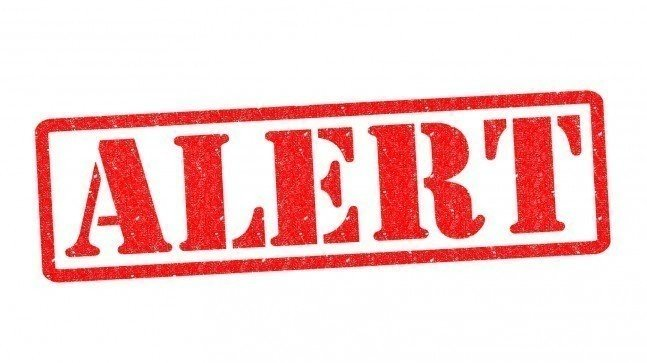

In [9]:
from PIL import Image
import glob

listeImages = []
for file_name in glob.glob("images/*.jpg"):
    image = Image.open(file_name)
    listeImages.append(image)

display(listeImages[1])

In [10]:
import chromadb
from chromadb.utils.data_loaders import ImageLoader
from chromadb.utils.embedding_functions import OpenCLIPEmbeddingFunction

BV_chromabd = chromadb.PersistentClient(path="db_storePortes")

chargeImages = ImageLoader()
VectorisationImages = OpenCLIPEmbeddingFunction()

chromadb = BV_chromabd.get_or_create_collection(
    name="portes_collection",
    data_loader=chargeImages,
    embedding_function=VectorisationImages
)


/opt/homebrew/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [19]:
import os

indexImage = []
CheminImages = []
dossierImages = "images/"

for index, image_name in enumerate(sorted(os.listdir(dossierImages))):
    if image_name.endswith(".jpg"):
        image_path = os.path.join(dossierImages, image_name)
        indexImage.append(str(index))
        CheminImages.append(image_path)

print(indexImage[:21])
print(CheminImages[:21])

['0', '1', '2', '3', '4', '5', '6', '7', '8']
['images/116628642bf8dcbb21a6594a7d2abebc.jpg', 'images/1682483127_papik-pro-p-otkritaya-dver-smail-png-17.jpg', 'images/1_MwRYMIeQ1WXmIDk7B6hH4w.jpg', 'images/81834LE2wZY.jpg', 'images/96ad9ab487e9ab5d346a700b5e970b3f.jpg', 'images/MXcERuxATFGxlFa-1600x900-noPad.jpg', 'images/Rue_Joubert_Porte.jpg', 'images/maxresdefault.jpg', 'images/unnamed.jpg']


In [20]:
chromadb.add(ids=indexImage, uris=CheminImages)

In [ ]:
chromadb.count()

9

In [ ]:
rechercheParText = chromadb.query(
    query_texts=["  ouverte "],
    n_results=1,
    include=["uris", "distances"]
)

rechercheParText

{'ids': [['3']],
 'embeddings': None,
 'documents': None,
 'uris': [['images/81834LE2wZY.jpg']],
 'included': ['uris', 'distances'],
 'data': None,
 'metadatas': None,
 'distances': [[0.7927896976470947]]}

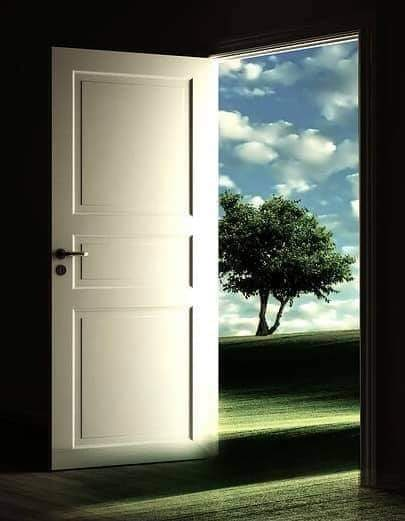

In [ ]:
from PIL import Image  # importer Image
from IPython.display import display  # importer display si tu es dans un notebook

for image_path in rechercheParText["uris"][0]:
    display(Image.open(image_path))


Dites quelque chose... (Écoute pendant 5 secondes)
Traitement de la voix...
Vous avez dit : pourrais-tu m'ouvrir la porte


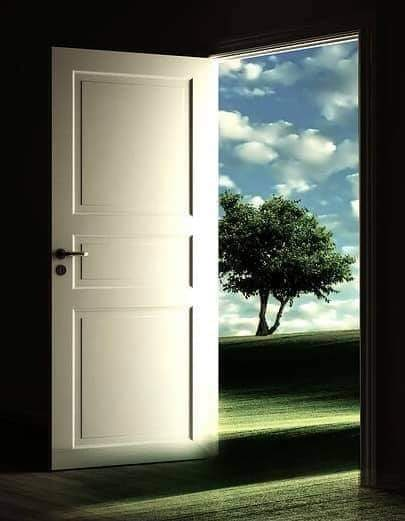

In [ ]:
import speech_recognition as sr
from PIL import Image 
from IPython.display import display 

# Initialisation du microphone
recognizer = sr.Recognizer()
microphone = sr.Microphone()

# Ajustement pour le bruit ambiant (optionnel, pour une meilleure précision)
with microphone as source:
    recognizer.adjust_for_ambient_noise(source)

print("Dites quelque chose... (Écoute pendant 5 secondes)")

# Capture de l'audio
with microphone as source:
    # Écoute pendant 5 secondes (ajustez timeout si besoin)
    audio = recognizer.listen(source, timeout=5)

print("Traitement de la voix...")

try:
    # Reconnaissance vocale avec Google (langue française par défaut)
    texte = recognizer.recognize_google(audio, language='fr-FR')
    print(f"Vous avez dit : {texte}")

    rechercheParText = chromadb.query(
    query_texts=[texte],
    n_results=1,
    include=["uris", "distances"]
)
    for image in rechercheParText["uris"][0]:
        display(Image.open(image))
except sr.UnknownValueError:
    print("Désolé, je n'ai pas compris ce que vous avez dit.")
except sr.RequestError as e:
    print(f"Erreur lors de la reconnaissance : {e}")

In [ ]:
import smtplib
from email.mime.text import MIMEText
from email.mime.multipart import MIMEMultipart

# Configuration (remplacez par vos infos)
expediteur = "yangassojeanyves@gmail.com"  # Votre adresse email
mot_de_passe_app = "trcsvsynczjnawyc"      # Mot de passe d'application Google
destinataire = "myteacherit2@gmail.com"    # Email du destinataire
sujet = "Information porte"
corps = "Bonjour ! Une personne vient de sonner à la porte."

# Création du message
message = MIMEMultipart()
message["From"] = expediteur
message["To"] = destinataire
message["Subject"] = sujet
message.attach(MIMEText(corps, "plain"))

try:
    # Connexion au serveur SMTP (pour Gmail : smtp.gmail.com, port 587)
    serveur = smtplib.SMTP("smtp.gmail.com", 587)
    serveur.starttls()  # Activation du chiffrement TLS
    serveur.login(expediteur, mot_de_passe_app)  # Authentification
    
    # Convertir le message en chaîne
    texte_message = message.as_string()
    
    # Envoi de l'email
    serveur.sendmail(expediteur, destinataire, texte_message)
    serveur.quit()  # Fermeture de la connexion
    
    print("Email envoyé avec succès !")

except Exception as e:
    print(f"Erreur lors de l'envoi : {e}")


Email envoyé avec succès !


In [ ]:
from gtts import gTTS
import os
import tempfile

# Boucle principale pour interagir
while True:
    texte = input("Entrez du texte à lire (ou 'quit' pour arrêter) : ")
    if texte.lower() == 'quit':
        break
    
    # Génération du MP3 avec gTTS (français)
    tts = gTTS(text=texte, lang='fr')
    
    # Fichier temporaire
    with tempfile.NamedTemporaryFile(delete=False, suffix='.mp3') as tmp_file:
        nom_fichier = tmp_file.name
        tts.save(nom_fichier)
    
    # Lecture avec le lecteur par défaut (Windows : start)
    os.system(f'start "" "{nom_fichier}"')
    
    # Attendre un peu pour que ça se lance, puis nettoyer (optionnel, après fermeture manuelle)
    input("Appuyez sur Entrée quand la lecture est finie pour continuer... ")
    try:
        os.remove(nom_fichier)
    except:
        pass  # Si encore en cours, ignore
    
    print("Texte lu !")

print("Programme TTS arrêté.")

Texte lu !
Texte lu !
Programme TTS arrêté.


In [21]:
data = chromadb.get(include=["uris", "embeddings"])

for id_, uri, vec in zip(data["ids"], data["uris"], data["embeddings"]):
    print(id_, uri, "→", len(vec), "valeurs :", vec[:5].round(3), "...")


0 images/116628642bf8dcbb21a6594a7d2abebc.jpg → 512 valeurs : [ 0.063  0.234 -0.11   0.051 -0.042] ...
1 images/1682483127_papik-pro-p-otkritaya-dver-smail-png-17.jpg → 512 valeurs : [ 0.029  0.085 -0.108  0.05  -0.055] ...
2 images/1_MwRYMIeQ1WXmIDk7B6hH4w.jpg → 512 valeurs : [ 0.014  0.092 -0.083 -0.011  0.   ] ...
3 images/81834LE2wZY.jpg → 512 valeurs : [ 0.006  0.012 -0.104 -0.04  -0.002] ...
4 images/96ad9ab487e9ab5d346a700b5e970b3f.jpg → 512 valeurs : [ 0.053  0.092 -0.014 -0.013  0.012] ...
5 images/MXcERuxATFGxlFa-1600x900-noPad.jpg → 512 valeurs : [ 0.024 -0.063  0.036 -0.005 -0.002] ...
6 images/Rue_Joubert_Porte.jpg → 512 valeurs : [ 0.043  0.203 -0.053  0.052 -0.031] ...
7 images/maxresdefault.jpg → 512 valeurs : [ 0.034  0.05   0.048 -0.015 -0.014] ...
8 images/unnamed.jpg → 512 valeurs : [ 0.04  -0.043 -0.041 -0.002  0.035] ...
